# Failure triage on real data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/5_practice/02_failure_triage.ipynb) &nbsp; Guide note: [guide-failure-triage](https://www.matthewwnuk.com/guide-failure-triage.html#controller)

When a robot fails, find the layer at fault before retraining anything. This notebook runs three of the
checks from the guide on real demonstrations: did the robot do what was commanded, is the failing
situation in the data, and do the demonstrations agree where it failed.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
d = data.libero(); A, S, EP, TK = d["action"], d["state"], d["episode"], d["task"]; f = data.libero_frames()

## Check 1: did the robot do what was commanded?

Compare each commanded step with the motion that followed. A healthy controller follows closely.

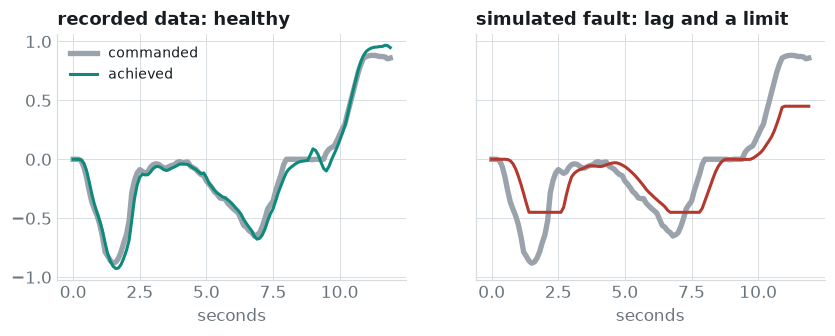

In [3]:
m = EP == 0; scale = 1.21; cmd = A[m][:-1, 1] * scale; moved = (S[m][1:, 1] - S[m][:-1, 1]) * 100; t = np.arange(len(cmd)) / 10
def faulty(c, delay=3, limit=0.45):                                             # a simulated fault: a lag and a speed limit
    smooth = np.convolve(c, np.ones(6) / 6, "full")[: len(c)]; return np.clip(np.r_[np.zeros(delay), smooth[:-delay]], -limit, limit)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.9), sharey=True)
for a, y, name, c in ((ax[0], moved, "recorded data: healthy", style.TEAL), (ax[1], faulty(cmd), "simulated fault: lag and a limit", style.RED)):
    a.plot(t[:120], cmd[:120], color=style.GREY, lw=3.5, label="commanded"); a.plot(t[:120], y[:120], color=c, label="achieved"); a.set_title(name); a.set_xlabel("seconds")
ax[0].legend(fontsize=9); plt.show()

Turn the comparison into three numbers: how well the two agree, by how much the response lags, and
whether it is clipped.

In [4]:
def diagnose(cmd, ach):
    lags = range(0, 8); lag = max(lags, key=lambda k: np.corrcoef(cmd[: len(cmd) - k], ach[k:])[0, 1]); gain = np.percentile(np.abs(ach), 99) / np.percentile(np.abs(cmd), 99)
    return np.corrcoef(cmd, ach)[0, 1], lag * 100, gain
for name, y in (("healthy", moved), ("faulty", faulty(cmd))):
    r, lag, gain = diagnose(cmd, y); print(f"{name:8s} correlation {r:.2f}   best lag {lag:3.0f} ms   peak response {gain:.0%} of the peak command")

healthy  correlation 0.99   best lag 100 ms   peak response 104% of the peak command
faulty   correlation 0.87   best lag 600 ms   peak response 48% of the peak command


## Check 3: is this situation in the data?

Embed frames with a pretrained image encoder and measure the distance from each to its nearest training
frame. Here the training set is half the episodes of seven tasks. Familiar frames come from the other
episodes of those tasks. Unfamiliar ones come from three tasks left out entirely.

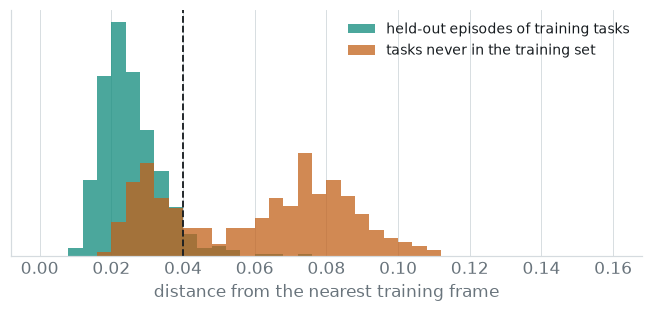

area under the curve 0.91;  at a 5% false-alarm rate the check catches 69% of unfamiliar frames


In [5]:
E, ep, task = f["clip"], f["episode"], f["task"]; rng = np.random.default_rng(0); eps = rng.permutation(np.unique(ep)); in_train_half = np.isin(ep, eps[: len(eps) // 2])
seen = np.isin(task, [0, 1, 2, 3, 4, 5, 6]); train = seen & in_train_half
def nearest(q): return 1 - (E[q] @ E[train].T).max(1)
familiar, unfamiliar = nearest(seen & ~in_train_half), nearest(~seen); bins = np.linspace(0, 0.16, 41); plt.figure(figsize=(7.4, 2.9))
plt.hist(familiar, bins, alpha=0.75, density=True, label="held-out episodes of training tasks"); plt.hist(unfamiliar, bins, alpha=0.75, density=True, label="tasks never in the training set")
thr = np.percentile(familiar, 95); plt.axvline(thr, color=style.INK, ls="--", lw=1.2); plt.xlabel("distance from the nearest training frame"); plt.yticks([]); plt.legend(fontsize=9); plt.show()
scores = np.r_[familiar, unfamiliar]; labels = np.r_[np.zeros(len(familiar)), np.ones(len(unfamiliar))]; order = np.argsort(-scores); tp = np.cumsum(labels[order]) / labels.sum(); fp = np.cumsum(1 - labels[order]) / (1 - labels).sum()
print(f"area under the curve {np.trapezoid(tp, fp):.2f};  at a 5% false-alarm rate the check catches {np.mean(unfamiliar > thr):.0%} of unfamiliar frames")

What does the check miss? Look at unfamiliar frames that scored as familiar.

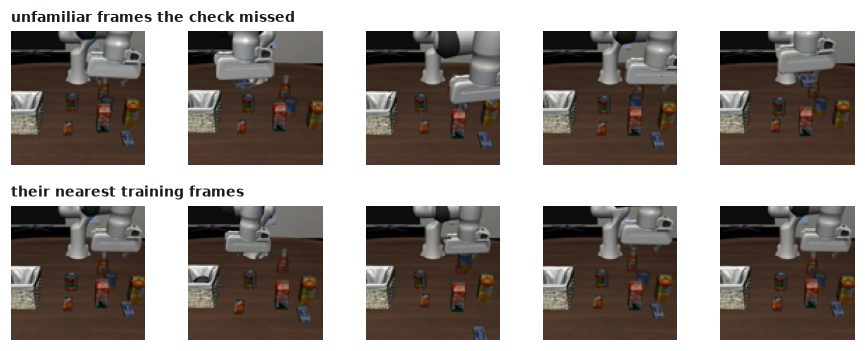

In [6]:
miss = np.flatnonzero(~seen)[np.argsort(unfamiliar)[:5]]; near = np.flatnonzero(train)[(E[miss] @ E[train].T).argmax(1)]; fig, ax = plt.subplots(2, 5, figsize=(8, 3.4))
for c in range(5): ax[0, c].imshow(f["thumbs"][miss[c]]); ax[1, c].imshow(f["thumbs"][near[c]]); style.bare(ax[0, c]); style.bare(ax[1, c])
ax[0, 0].set_title("unfamiliar frames the check missed", fontsize=9, loc="left"); ax[1, 0].set_title("their nearest training frames", fontsize=9, loc="left"); plt.tight_layout(); plt.show()

## Check 4: do the demonstrations agree here?

Where the data does cover a situation, wide spread between demonstrations means the policy is being
taught several answers.

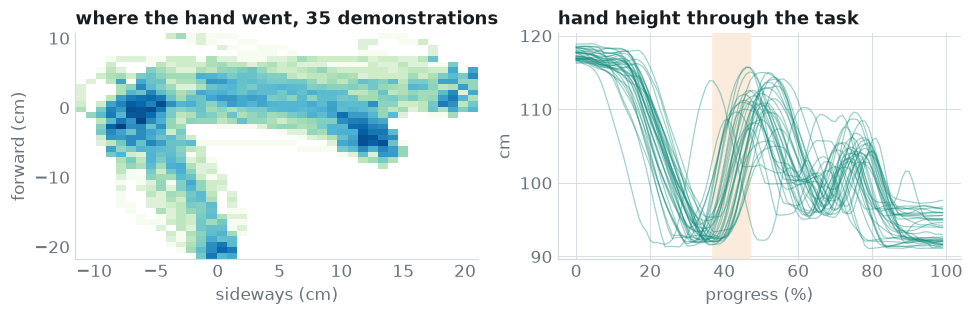

demonstrations disagree most at 42% of the episode, by 5.8 cm; the median spread is 3.4 cm


In [7]:
ids = np.unique(EP[TK == 8]); Z = np.array([np.interp(np.linspace(0, 1, 100), np.linspace(0, 1, (EP == e).sum()), S[EP == e][:, 2] * 100) for e in ids]); sd = Z.std(0); k = int(np.argmax(sd[10:90])) + 10
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
xy = S[TK == 8][:, :2] * 100; ax[0].hist2d(xy[:, 1], xy[:, 0], bins=40, cmap="GnBu", norm="log"); ax[0].set_title(f"where the hand went, {len(ids)} demonstrations"); ax[0].set_xlabel("sideways (cm)"); ax[0].set_ylabel("forward (cm)"); ax[0].grid(False)
for z_ in Z: ax[1].plot(z_, color=style.TEAL, lw=0.8, alpha=0.4)
ax[1].axvspan(k - 5, k + 5, color="#FBEBDD"); ax[1].set_title("hand height through the task"); ax[1].set_xlabel("progress (%)"); ax[1].set_ylabel("cm"); plt.tight_layout(); plt.show()
print(f"demonstrations disagree most at {k}% of the episode, by {sd[k]:.1f} cm; the median spread is {np.median(sd):.1f} cm")

A coverage gap needs more data. A consistency problem needs cleaner data. They have opposite cures,
which is why they are separate checks.

## Things to try

- Add a constant offset to the achieved motion and extend `diagnose` to report it.
- Use raw pixels (`f["pixels"]`) instead of the encoder's features for check 3. How much worse is it?
- Average the distance over all four frames of an episode before thresholding. Does that reduce the misses?